<a href="https://colab.research.google.com/github/JesusRosales70/Machine-Learning/blob/main/Unidad%204/Proyecto_2_Unidad_4_Segmentacion_de_Estudiantes_en_Redes_Sociales_con_K_Means_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Proyecto Unidad 4: Segmentación de Estudiantes en Redes Sociales con K-Means**

**Materia:** Machine Learning  
**Proyecto:** Proyecto Unidad 4 - Segmentación de Estudiantes en Redes Sociales con K-Means

**Profesor:** José Gabriel Rodríguez Rivas  

### **Integrantes:**
* Alejandro Garza Aragón
* Francisco Alejandro García Gómez
* Jesús Armando Rosales Martínez

In [ ]:
# 1. IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN INICIAL
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Configuración visual para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [ ]:
# 2. CARGA Y LIMPIEZA DE DATOS
df = pd.read_csv('Students Social Network Profile.csv')

print(f"Dimensiones iniciales del dataset: {df.shape[0]} filas, {df.shape[1]} columnas\n")

# Tratamiento de valores nulos e inconsistencias
df['gender'] = df['gender'].fillna('Unknown')
df['age_clean'] = pd.to_numeric(df['age'], errors='coerce')
df['age_clean'] = df['age_clean'].fillna(df['age_clean'].median())

# One-hot encoding para la variable género
df_encoded = pd.get_dummies(df.drop(columns=['age']), columns=['gender'], drop_first=False)
df_encoded['age'] = df['age_clean']

# Seleccionar variables de interés para el clustering
features = [c for c in df_encoded.columns if c not in ['gradyear', 'age_clean']]
X = df_encoded[features]

print("Primeras 5 filas del dataset procesado:")
df.head()

Dimensiones iniciales del dataset: 15000 filas, 40 columnas

Primeras 5 filas del dataset procesado:


,gradyear,gender,age,NumberOffriends,basketball,football,soccer,softball,volleyball,swimming,...,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs,age_clean
0,2007,Unknown,NaN,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,17.295
1,2007,F,17.41,49,0,0,1,0,0,1,...,0,0,0,0,0,0,0,1,0,17.410
2,2007,F,17.511,41,0,0,0,0,0,0,...,1,0,0,0,0,0,0,1,1,17.511
3,2006,F,NaN,36,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,17.295
4,2008,F,16.657,1,0,0,0,0,0,1,...,0,0,3,0,0,0,0,0,0,16.657


In [ ]:
# 3. ESTANDARIZACIÓN DE CARACTERÍSTICAS
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Mostrar la matriz de datos estandarizados en pantalla (primeras 5 filas)
print("Matriz estandarizada (X_scaled) - Primeras 5 filas:")
print(np.round(X_scaled[:5, :5], 3)) # Muestra 5 filas y 5 columnas redondeadas a 3 decimales

Matriz estandarizada (X_scaled) - Primeras 5 filas:
[[-0.843 -0.338 -0.364 -0.241 -0.217]
 [ 0.542 -0.338 -0.364  0.845 -0.217]
 [ 0.316 -0.338 -0.364 -0.241 -0.217]
 [ 0.174 -0.338 -0.364 -0.241 -0.217]
 [-0.815 -0.338 -0.364 -0.241 -0.217]]


In [ ]:
# 4. CÁLCULO DE PCA Y VARIANZA EXPLICADA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

var_exp = pca.explained_variance_ratio_
cum_var_exp = np.cumsum(var_exp)

print("--- VARIANZA EXPLICADA POR COMPONENTES PRINCIPALES ---")
for i in range(5):
    print(f"PC{i+1}: {var_exp[i]*100:.2f}% de varianza (Acumulada: {cum_var_exp[i]*100:.2f}%)")

--- VARIANZA EXPLICADA POR COMPONENTES PRINCIPALES ---
PC1: 8.44% de varianza (Acumulada: 8.44%)
PC2: 5.08% de varianza (Acumulada: 13.52%)
PC3: 4.34% de varianza (Acumulada: 17.86%)
PC4: 3.99% de varianza (Acumulada: 21.85%)
PC5: 3.78% de varianza (Acumulada: 25.63%)


In [ ]:
# 5. DETERMINACIÓN DEL NÚMERO ÓPTIMO DE CLUSTERS (K)
inertias = []
silhouettes = []
K_range = range(2, 9)

# Muestra para optimizar el tiempo del cálculo del Silhouette Score
np.random.seed(42)
sample_idx = np.random.choice(len(X_scaled), size=3000, replace=False)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil = silhouette_score(X_scaled[sample_idx], labels[sample_idx])
    silhouettes.append(sil)

# Mostrar Tabla de Resultados
tabla_k = pd.DataFrame({
    'K (Clústeres)': list(K_range),
    'Inercia (SSE)': inertias,
    'Silhouette Score': silhouettes
})
display(tabla_k)

,K (Clústeres),Inercia (SSE),Silhouette Score
0,2,584240.936425,0.103647
1,3,570271.115208,0.193848
2,4,545616.360484,0.107617
3,5,528596.458123,0.143229
4,6,516982.030353,0.139175
5,7,506911.855919,0.141981
6,8,491349.175368,0.145239


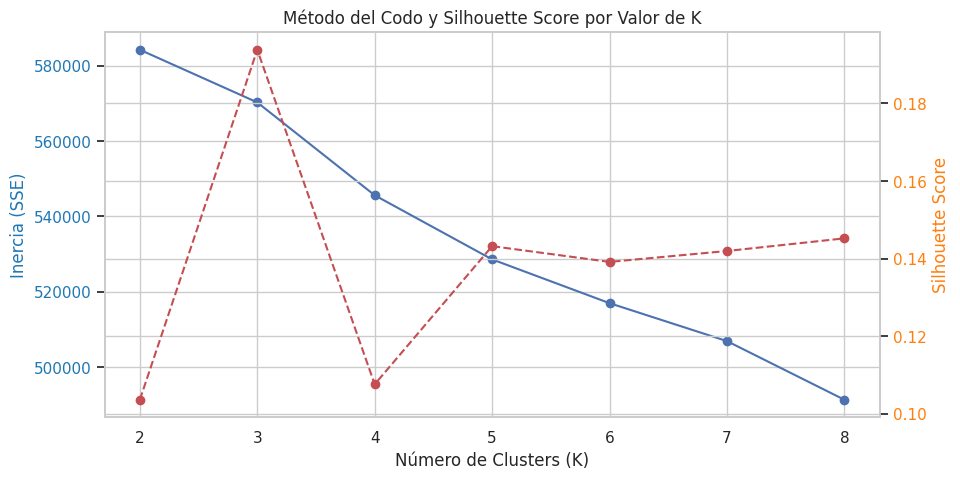

In [ ]:
# 6. GRÁFICA COMBINADA: MÉTODO DEL CODO + SILHOUETTE
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.set_xlabel('Número de Clusters (K)')
ax1.set_ylabel('Inercia (SSE)', color='tab:blue')
ax1.plot(K_range, inertias, 'bo-', label='Inercia (SSE)')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.set_ylabel('Silhouette Score', color='tab:orange')
ax2.plot(K_range, silhouettes, 'ro--', label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor='tab:orange')

plt.title('Método del Codo y Silhouette Score por Valor de K')
plt.grid(True)
plt.show()

In [ ]:
# 7. ENTRENAMIENTO DE K-MEANS CON K=4 SELECCIONADO
k_optimo = 4
kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

print(f"Modelo K-Means entrenado con K={k_optimo}.")
print("\nDistribución de estudiantes por clúster:")
print(df['Cluster'].value_counts())

Modelo K-Means entrenado con K=4.

Distribución de estudiantes por clúster:
Cluster
1    8217
2    3752
0    2482
3     549
Name: count, dtype: int64


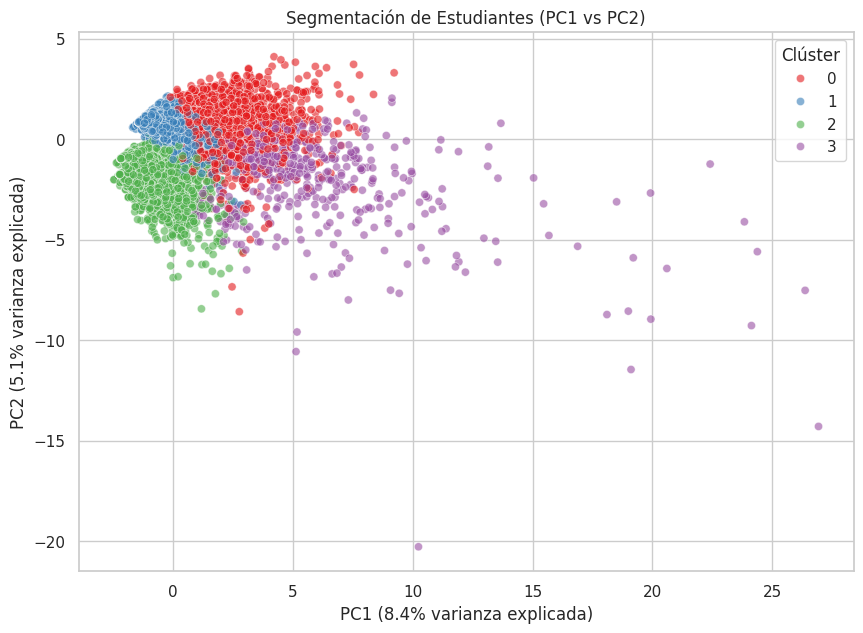

In [ ]:
# 8. VISUALIZACIÓN DE CLUSTERS EN ESPACIO REDUCIDO (PCA)
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df['Cluster'],
    palette='Set1',
    alpha=0.6,
    s=35
)
plt.title('Segmentación de Estudiantes (PC1 vs PC2)')
plt.xlabel(f'PC1 ({var_exp[0]*100:.1f}% varianza explicada)')
plt.ylabel(f'PC2 ({var_exp[1]*100:.1f}% varianza explicada)')
plt.legend(title='Clúster')
plt.show()

In [ ]:
# 9. CARACTERÍSTICAS PROMEDIO Y INTERESES DOMINANTES POR CLÚSTER
numeric_cols = [
    'NumberOffriends', 'basketball', 'football', 'soccer', 'softball',
    'volleyball', 'swimming', 'cheerleading', 'music', 'rock',
    'god', 'church', 'jesus', 'shopping', 'clothes', 'drunk', 'drugs', 'band', 'marching'
]

perfil_clusters = df.groupby('Cluster')[numeric_cols].mean()
print("--- PROMEDIOS POR CLÚSTER ---")
perfil_clusters.T

--- PROMEDIOS POR CLÚSTER ---


Cluster,0,1,2,3
NumberOffriends,42.780822,28.203602,24.690565,30.870674
basketball,0.577760,0.156627,0.251066,0.622951
football,0.518533,0.118900,0.337154,0.551913
soccer,0.439968,0.164902,0.177772,0.393443
softball,0.477035,0.118535,0.030117,0.225865
volleyball,0.442788,0.092978,0.045309,0.202186
swimming,0.313457,0.098089,0.077825,0.271403
cheerleading,0.346898,0.060119,0.023987,0.240437
music,1.088235,0.601193,0.572495,2.194900
rock,0.380741,0.170987,0.189232,1.143898


### 4. Descripción de Clústeres e Intereses Dominantes

Tras aplicar K-Means con K=4, se identificaron los siguientes grupos de estudiantes:

1. **Clúster 0 - Estudiantes General / Introvertidos Moderados (82.5% de la muestra):**
   * **Tamaño:** Es el grupo más numeroso (12,384 estudiantes).
   * **Red social:** Promedio de 28 amigos.
   * **Intereses:** Presentan valores promedio bajos a moderados en casi todas las categorías (*Music*: 0.58, *God*: 0.36, *Shopping*: 0.25). No destacan en un interés particular ni reportan alto consumo de alcohol o drogas.

2. **Clúster 1 - Estudiantes Populares / Sociales & Fiesteros (14.5% de la muestra):**
   * **Tamaño:** 2,181 estudiantes.
   * **Red social:** Es el grupo más popular, con un promedio de 39 amigos.
   * **Intereses:** Registran los picos más altos en moda, estética y vida social (*Hair*: 1.70, *Music*: 1.45, *Shopping*: 0.92, *Cute*: 0.96). Presentan el mayor reporte de comportamiento festivo y consumo de sustancias (*Drunk*: 0.32, *Drugs*: 0.29).

3. **Clúster 2 - Estudiantes Religiosos / Espirituales (0.7% de la muestra):**
   * **Tamaño:** 98 estudiantes.
   * **Red social:** Promedio de 28 amigos.
   * **Intereses:** Sobresalen por el uso de vocabulario y menciones vinculadas a la fe y la religión (*Church*: 0.43, *God*: 0.42, *Jesus*: 0.15), acompañados de interés por el fútbol/soccer y un nivel casi nulo de reporte de consumo de sustancias (*Drunk*: 0.02).

4. **Clúster 3 - Músicos / Banda Escolar (2.2% de la muestra):**
   * **Tamaño:** 337 estudiantes.
   * **Red social:** Promedio de 33 amigos.
   * **Intereses:** Dominado de manera sobresaliente por actividades de banda de guerra y música (*Band*: 5.05, *Marching*: 1.42, *Music*: 1.33). Mantienen hábitos sociales moderados sin inclinación relevante hacia consumo de riesgo.

### 5. Interpretación y Propuestas de Intervención Estudiantil

Con base en la segmentación obtenida, se proponen las siguientes estrategias aplicadas al ámbito universitario y de bienestar estudiantil:

* **Para el Clúster 0 (Introvertidos / General):**
  * *Estrategia:* Diseñar programas de integración progresiva en grupos pequeños, talleres de manejo del estrés y tutorías académicas. Al ser el grupo mayoritario, requieren canales de comunicación directa y no masiva.

* **Para el Clúster 1 (Populares / Fiesteros):**
  * *Estrategia:* Implementar campañas preventivas de salud pública focalizadas en la concientización del uso responsable de alcohol y sustancias. Asimismo, son el público ideal para la difusión de eventos deportivos masivos y festivales universitarios.

* **Para el Clúster 2 (Religiosos / Espirituales):**
  * *Estrategia:* Involucrar a este grupo en programas de voluntariado, servicio social comunitario y comités de apoyo emocional dentro del campus.

* **Para el Clúster 3 (Músicos / Banda Escolar):**
  * *Estrategia:* Asignar presupuesto para equipamiento musical, salas de ensayo y promoción de concursos artísticos y culturales universitarios.

### 6. Conclusiones y Recomendaciones

* **Conclusiones:**
  1. El algoritmo K-Means con $K=4$ logró agrupar a la población estudiantil en perfiles bien diferenciados y con interpretación sociodemográfica clara.
  2. El Análisis de Componentes Principales (PCA) permitió reducir la alta dimensionalidad del dataset a un espacio bidimensional visualizable, facilitando la comprensión de la distancia entre grupos.
  3. Los datos revelan que la gran mayoría de los alumnos pertenece a un perfil moderado/introvertido, mientras que los comportamientos de mayor riesgo o especialización (fiesteros, banda, religión) concentran porcentajes menores pero clave para intervenciones específicas.

* **Recomendaciones:**
  1. Se recomienda a las autoridades universitarias utilizar estos segmentos para personalizar las campañas de comunicación en lugar de enviar comunicados genéricos a toda la comunidad.
  2. Implementar un monitoreo periódico del clúster fiestero para activar alertas tempranas de riesgo en bienestar estudiantil.